In [22]:
## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

loss= 'RMSE'
losses= ['RMSE', 'NSE']

method= 'LocalHYSEP'
methods= ['USGS', 'Furey', 'Eckhardt', 'LocalHYSEP']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
# model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']

# if model=='HBV':
#     dyn= 'parBETA_parBETAET_'

# if model=='marrmot_PRMS':
#     dyn= 'alpha_cgw_scx_tt_'

# if model=='HBV_capillary':
#     dyn= 'parBETA_parBETAET_parK0_parUZL_'

if test== 'PUB':
    n=11
if test== 'PUR':
    n=8

    
import numpy as np
import os

def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    std_obs = np.std(obs)
    std_sim = np.std(sim)

    if std_obs == 0:
        return np.nan

    alpha = std_sim / std_obs

    mean_obs = np.mean(obs)
    if mean_obs == 0:
        return np.nan

    beta = np.mean(sim) / mean_obs

    return 1 - np.sqrt(
        (r - 1) ** 2 +
        (alpha - 1) ** 2 +
        (beta - 1) ** 2
    )


def calc_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return (np.sum(sim) - den) / den


def calc_abs_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return np.abs(np.sum(sim) - den) / den

def calc_rmse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) == 0:
        return np.nan

    return np.sqrt(np.mean((obs - sim) ** 2))


models= ['HBV', 'HBV_capillary', 'marrmot_PRMS']
# models= ['HBV', 'marrmot_PRMS']

for k in range(len(models)):
    model= models[k]

    if model=='HBV':
        dyn= 'parBETA_parBETAET_'

    if model=='marrmot_PRMS':
        dyn= 'alpha_cgw_scx_tt_'

    if model=='HBV_capillary':
        dyn= 'parBETA_parBETAET_parK0_parUZL_'

# ============================================================
# Metric functions
# ============================================================



# ============================================================
# Containers
# ============================================================

    metrics_old = {
        "NSE": [],
        "KGE": [],
        "Bias": [],
        "AbsBias": [],
        # "RMSE_low": [],
        # "RMSE_high": [],
        "NSE_low": [],
        "NSE_high": [],
        "Bias_low": [],
        "Bias_high": [],
        "AbsBias_low": [],
        "AbsBias_high": [],
    }

    metrics_new = {
        "NSE": [],
        "KGE": [],
        "Bias": [],
        "AbsBias": [],
        # "RMSE_low": [],
        # "RMSE_high": [],
        "NSE_low": [],
        "NSE_high": [],
        "Bias_low": [],
        "Bias_high": [],
        "AbsBias_low": [],
        "AbsBias_high": [],
    }

    # ============================================================
    # Loop over folds
    # ============================================================

    for i in range(1, n):


        if test== 'PUB':
            folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/{method}_{objectives[1]}/{i}/"

            sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/OUTPUTS_PUB_{objectives[0]}/{i}/"
            # gauge = np.load(
            #     f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy")
 

        if test== 'PUR':
            # folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_{objectives[1]}/Region_{i}/"
            folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR/{method}_{objectives[1]}/{loss}/{model}/Region_{i}/"

            # "Z:\OUTPUTS_Paper1v2\PUR\Furey_Multi\RMSE\HBV\Region_1"

            sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR/Single/{loss}/{model}/Region_{i}/"


        obs_flow = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy")
        )

        sim_old = np.load(
            os.path.join(sfolder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
            # os.path.join(sfolder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_Multi/Region_{i}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"
            )
        

        sim_new = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"
        )

        sim_old = np.squeeze(sim_old)
        sim_new = np.squeeze(sim_new)

        # --------------------------------------------------------
        # Loop over basins
        # --------------------------------------------------------
        for k in range(obs_flow.shape[1]):

            obs = obs_flow[:, k]
            old = sim_old[:, k]
            new = sim_new[:, k]

            # =====================================================
            # Overall metrics
            # =====================================================
            metrics_old["NSE"].append(calc_nse(obs, old))
            metrics_new["NSE"].append(calc_nse(obs, new))

            metrics_old["KGE"].append(calc_kge(obs, old))
            metrics_new["KGE"].append(calc_kge(obs, new))

            metrics_old["Bias"].append(calc_bias(obs, old))
            metrics_new["Bias"].append(calc_bias(obs, new))

            metrics_old["AbsBias"].append(calc_abs_bias(obs, old))
            metrics_new["AbsBias"].append(calc_abs_bias(obs, new))

            # =====================================================
            # Low / High flow
            # =====================================================
            threshold = np.median(obs)
            # print(threshold, np.mean(obs))

            low = obs <= threshold
            high = obs > threshold


            # print(f"Num_overall:{np.sum((obs - new) ** 2)}")
            # print(f"Den_overall:{np.sum((obs - np.mean(obs)) ** 2)}")
            # print(f"Overall Mean:{np.mean(obs)}")

            # print(f"Num_high:{np.sum((obs[high]- new[high])** 2)}")
            # print(f":Den_high:{np.sum((obs[high] - np.mean(obs[high])) ** 2)}")
            # print(f"High Mean:{np.mean(obs[high])}")


            # print(f"Num_low:{np.sum((obs[low] - new[low]) ** 2)}")
            # print(f"Den_low:{np.sum((obs[low] - np.mean(obs[low])) ** 2)}")
            # print(f"Low Mean:{np.mean(obs[low])}")


            # ---------------- Low flow ----------------
            if np.sum(low) > 2:
                # metrics_old["RMSE_low"].append(calc_rmse(obs[low], old[low]))
                # metrics_new["RMSE_low"].append(calc_rmse(obs[low], new[low]))

                metrics_old["NSE_low"].append(calc_nse(obs[low], old[low]))
                metrics_new["NSE_low"].append(calc_nse(obs[low], new[low]))

                metrics_old["Bias_low"].append(calc_bias(obs[low], old[low]))
                metrics_new["Bias_low"].append(calc_bias(obs[low], new[low]))

                metrics_old["AbsBias_low"].append(
                    calc_abs_bias(obs[low], old[low])
                )
                metrics_new["AbsBias_low"].append(
                    calc_abs_bias(obs[low], new[low])
                )

            # ---------------- High flow ----------------
            if np.sum(high) > 2:

                # metrics_old["RMSE_high"].append(calc_rmse(obs[high], old[high]))
                # metrics_new["RMSE_high"].append(calc_rmse(obs[high], new[high]))

                metrics_old["NSE_high"].append(calc_nse(obs[high], old[high]))
                metrics_new["NSE_high"].append(calc_nse(obs[high], new[high]))

                metrics_old["Bias_high"].append(calc_bias(obs[high], old[high]))
                metrics_new["Bias_high"].append(calc_bias(obs[high], new[high]))

                metrics_old["AbsBias_high"].append(
                    calc_abs_bias(obs[high], old[high])
                )
                metrics_new["AbsBias_high"].append(
                    calc_abs_bias(obs[high], new[high])
                )

    # ============================================================
    # Print comparison
    # ============================================================

    # print("\n" + "=" * 60)
    print(f"{test} Test TOTAL FLOW COMPARISON ({model} 1989-1999) using {method} for baseflow separation with {loss} function.")
    # print("=" * 60)

    metric_order = [
        "NSE",
        "KGE",
        "Bias",
        "AbsBias",
        # "RMSE_low",
        # "RMSE_high",
        "NSE_low",
        "NSE_high",
        "Bias_low",
        "Bias_high",
        "AbsBias_low",
        "AbsBias_high",
    ]

    for metric in metric_order:
        old = np.nanmedian(metrics_old[metric])
        new = np.nanmedian(metrics_new[metric])
        print(f"{metric:<13}: {old:8.3f} → {new:8.3f}")

    print("=" * 60)

PUR Test TOTAL FLOW COMPARISON (HBV 1989-1999) using LocalHYSEP for baseflow separation with RMSE function.
NSE          :    0.633 →    0.645
KGE          :    0.650 →    0.645
Bias         :   -0.034 →   -0.043
AbsBias      :    0.128 →    0.123
NSE_low      :   -3.752 →   -3.811
NSE_high     :    0.576 →    0.574
Bias_low     :    0.304 →    0.305
Bias_high    :   -0.070 →   -0.070
AbsBias_low  :    0.447 →    0.441
AbsBias_high :    0.143 →    0.141
PUR Test TOTAL FLOW COMPARISON (HBV_capillary 1989-1999) using LocalHYSEP for baseflow separation with RMSE function.
NSE          :    0.621 →    0.637
KGE          :    0.628 →    0.646
Bias         :   -0.037 →   -0.039
AbsBias      :    0.130 →    0.123
NSE_low      :   -4.100 →   -3.554
NSE_high     :    0.553 →    0.558
Bias_low     :    0.386 →    0.327
Bias_high    :   -0.069 →   -0.076
AbsBias_low  :    0.484 →    0.450
AbsBias_high :    0.141 →    0.135
PUR Test TOTAL FLOW COMPARISON (marrmot_PRMS 1989-1999) using LocalHYSEP f

In [23]:
## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

loss= 'RMSE'
losses= ['RMSE', 'NSE']

method= 'LocalHYSEP'
methods= ['USGS', 'Furey', 'Eckhardt', 'LocalHYSEP']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
# model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']

# if model=='HBV':
#     dyn= 'parBETA_parBETAET_'

# if model=='marrmot_PRMS':
#     dyn= 'alpha_cgw_scx_tt_'

# if model=='HBV_capillary':
#     dyn= 'parBETA_parBETAET_parK0_parUZL_'

if test== 'PUB':
    n=11
if test== 'PUR':
    n=8

    
import numpy as np
import os

def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    std_obs = np.std(obs)
    std_sim = np.std(sim)

    if std_obs == 0:
        return np.nan

    alpha = std_sim / std_obs

    mean_obs = np.mean(obs)
    if mean_obs == 0:
        return np.nan

    beta = np.mean(sim) / mean_obs

    return 1 - np.sqrt(
        (r - 1) ** 2 +
        (alpha - 1) ** 2 +
        (beta - 1) ** 2
    )


def calc_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return (np.sum(sim) - den) / den


def calc_abs_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return np.abs(np.sum(sim) - den) / den


models= ['HBV', 'HBV_capillary', 'marrmot_PRMS']
# models= ['HBV', 'marrmot_PRMS']

for k in range(len(models)):
    model= models[k]

    if model=='HBV':
        dyn= 'parBETA_parBETAET_'

    if model=='marrmot_PRMS':
        dyn= 'alpha_cgw_scx_tt_'

    if model=='HBV_capillary':
        dyn= 'parBETA_parBETAET_parK0_parUZL_'

# ============================================================
# Metric functions
# ============================================================



# ============================================================
# Containers
# ============================================================

    metrics_old = {
        "NSE": [],
        "KGE": [],
        "Bias": [],
        "AbsBias": [],
        "NSE_low": [],
        "NSE_high": [],
        "Bias_low": [],
        "Bias_high": [],
        "AbsBias_low": [],
        "AbsBias_high": [],
    }

    metrics_new = {
        "NSE": [],
        "KGE": [],
        "Bias": [],
        "AbsBias": [],
        "NSE_low": [],
        "NSE_high": [],
        "Bias_low": [],
        "Bias_high": [],
        "AbsBias_low": [],
        "AbsBias_high": [],
    }

    # ============================================================
    # Loop over folds
    # ============================================================

    for i in range(1, n):


        if test== 'PUB':
            folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/{method}_{objectives[1]}/{i}/"

            sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/OUTPUTS_PUB_{objectives[0]}/{i}/"
            # gauge = np.load(
            #     f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy")
 

        if test== 'PUR':
            # folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_{objectives[1]}/Region_{i}/"
            folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR/{method}_{objectives[1]}/{loss}/{model}/Region_{i}/"

            # "Z:\OUTPUTS_Paper1v2\PUR\Furey_Multi\RMSE\HBV\Region_1"

            sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR/Single/{loss}/{model}/Region_{i}/"

            # f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_{objectives[0]}/Region_{i}/"


        obs_flow = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy")
        )

        sim_old = np.load(os.path.join(sfolder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy"))

            # os.path.join(sfolder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_Multi/Region_{i}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"

        

        sim_new = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"
        )

        sim_old = np.squeeze(sim_old)
        sim_new = np.squeeze(sim_new)

        # --------------------------------------------------------
        # Loop over basins
        # --------------------------------------------------------
        for k in range(obs_flow.shape[1]):

            obs = obs_flow[:, k]
            old = sim_old[:, k]
            new = sim_new[:, k]

            # =====================================================
            # Overall metrics
            # =====================================================
            metrics_old["NSE"].append(calc_nse(obs, old))
            metrics_new["NSE"].append(calc_nse(obs, new))

            metrics_old["KGE"].append(calc_kge(obs, old))
            metrics_new["KGE"].append(calc_kge(obs, new))

            metrics_old["Bias"].append(calc_bias(obs, old))
            metrics_new["Bias"].append(calc_bias(obs, new))

            metrics_old["AbsBias"].append(calc_abs_bias(obs, old))
            metrics_new["AbsBias"].append(calc_abs_bias(obs, new))

            # =====================================================
            # Low / High flow
            # =====================================================
            threshold = np.median(obs)
            # print(threshold, np.mean(obs))

            low = obs <= threshold
            high = obs > threshold


            # print(f"Num_overall:{np.sum((obs - new) ** 2)}")
            # print(f"Den_overall:{np.sum((obs - np.mean(obs)) ** 2)}")
            # print(f"Overall Mean:{np.mean(obs)}")

            # print(f"Num_high:{np.sum((obs[high]- new[high])** 2)}")
            # print(f":Den_high:{np.sum((obs[high] - np.mean(obs[high])) ** 2)}")
            # print(f"High Mean:{np.mean(obs[high])}")


            # print(f"Num_low:{np.sum((obs[low] - new[low]) ** 2)}")
            # print(f"Den_low:{np.sum((obs[low] - np.mean(obs[low])) ** 2)}")
            # print(f"Low Mean:{np.mean(obs[low])}")


            # ---------------- Low flow ----------------
            if np.sum(low) > 2:

                metrics_old["NSE_low"].append(calc_nse(obs[low], old[low]))
                metrics_new["NSE_low"].append(calc_nse(obs[low], new[low]))

                metrics_old["Bias_low"].append(calc_bias(obs[low], old[low]))
                metrics_new["Bias_low"].append(calc_bias(obs[low], new[low]))

                metrics_old["AbsBias_low"].append(
                    calc_abs_bias(obs[low], old[low])
                )
                metrics_new["AbsBias_low"].append(
                    calc_abs_bias(obs[low], new[low])
                )

            # ---------------- High flow ----------------
            if np.sum(high) > 2:

                metrics_old["NSE_high"].append(calc_nse(obs[high], old[high]))
                metrics_new["NSE_high"].append(calc_nse(obs[high], new[high]))

                metrics_old["Bias_high"].append(calc_bias(obs[high], old[high]))
                metrics_new["Bias_high"].append(calc_bias(obs[high], new[high]))

                metrics_old["AbsBias_high"].append(
                    calc_abs_bias(obs[high], old[high])
                )
                metrics_new["AbsBias_high"].append(
                    calc_abs_bias(obs[high], new[high])
                )

    # ============================================================
    # Print comparison
    # ============================================================

    # print("\n" + "=" * 60)
    print(f"{test} Test  BASEFLOW COMPARISON ({model} 1989-1999) using {method} for baseflow separation and {loss} function")
    # print("=" * 60)

    metric_order = [
        "NSE",
        "KGE",
        "Bias",
        "AbsBias",
        "NSE_low",
        "NSE_high",
        "Bias_low",
        "Bias_high",
        "AbsBias_low",
        "AbsBias_high",
    ]

    for metric in metric_order:
        old = np.nanmedian(metrics_old[metric])
        new = np.nanmedian(metrics_new[metric])
        print(f"{metric:<13}: {old:8.3f} → {new:8.3f}")

    print("=" * 60)
    

PUR Test  BASEFLOW COMPARISON (HBV 1989-1999) using LocalHYSEP for baseflow separation and RMSE function
NSE          :    0.394 →    0.516
KGE          :    0.405 →    0.535
Bias         :   -0.056 →   -0.042
AbsBias      :    0.284 →    0.217
NSE_low      :   -4.130 →   -3.771
NSE_high     :    0.134 →    0.249
Bias_low     :    0.418 →    0.305
Bias_high    :   -0.122 →   -0.087
AbsBias_low  :    0.563 →    0.488
AbsBias_high :    0.275 →    0.210
PUR Test  BASEFLOW COMPARISON (HBV_capillary 1989-1999) using LocalHYSEP for baseflow separation and RMSE function
NSE          :    0.268 →    0.516
KGE          :    0.243 →    0.521
Bias         :   -0.300 →   -0.044
AbsBias      :    0.409 →    0.227
NSE_low      :   -2.749 →   -3.541
NSE_high     :   -0.087 →    0.258
Bias_low     :    0.197 →    0.298
Bias_high    :   -0.361 →   -0.092
AbsBias_low  :    0.538 →    0.489
AbsBias_high :    0.427 →    0.214
PUR Test  BASEFLOW COMPARISON (marrmot_PRMS 1989-1999) using LocalHYSEP for base

In [ ]:
import os
import pandas as pd
import numpy

methods= ['USGS', 'Furey', 'Eckhardt', 'LocalHYSEP']

models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']

if model=='HBV':
        dyn= 'parBETA_parBETAET_'

if model=='marrmot_PRMS':
        dyn= 'alpha_cgw_scx_tt_'

if model=='HBV_capillary':
        dyn= 'parBETA_parBETAET_parK0_parUZL_'
def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den

for i in range(1,11):

    obs_flow= np.load(f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/{method}_Multi/{i}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy")
    sim_flow= np.load(f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/{method}_Multi/{i}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
    sim_flow= sim_flow.squeeze()

    for k in range(obs_flow.shape[1]):
        obs= obs_flow[:,k]
        sim= sim_flow[:,k]
        nse= calc_nse(obs,sim)

Processing: Furey_HBV
Fold 1: 52 basins, valid NSE = 52
Fold 2: 54 basins, valid NSE = 106
Fold 3: 52 basins, valid NSE = 158
Fold 4: 51 basins, valid NSE = 209
Fold 5: 54 basins, valid NSE = 263
Fold 6: 47 basins, valid NSE = 310
Fold 7: 56 basins, valid NSE = 366
Fold 8: 55 basins, valid NSE = 421
Fold 9: 54 basins, valid NSE = 475
Fold 10: 56 basins, valid NSE = 531

Furey_HBV: N = 531, Mean = 0.4720, Median = 0.6921, Min = -14.4302, Max = 0.9446
Processing: Furey_marrmot_PRMS
Fold 1: 52 basins, valid NSE = 52
Fold 2: 54 basins, valid NSE = 106
Fold 3: 52 basins, valid NSE = 158
Fold 4: 51 basins, valid NSE = 209
Fold 5: 54 basins, valid NSE = 263
Fold 6: 47 basins, valid NSE = 310
Fold 7: 56 basins, valid NSE = 366
Fold 8: 55 basins, valid NSE = 421
Fold 9: 54 basins, valid NSE = 475
Fold 10: 56 basins, valid NSE = 531

Furey_marrmot_PRMS: N = 531, Mean = 0.4860, Median = 0.6779, Min = -10.7962, Max = 0.9450


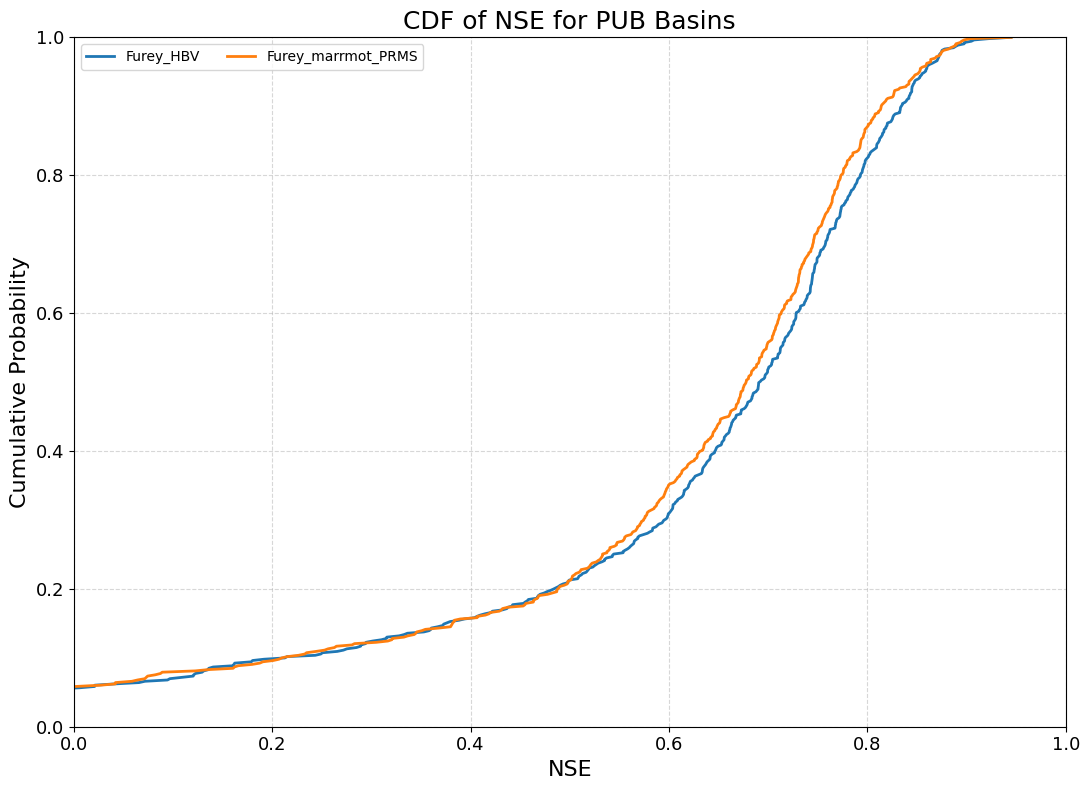

In [18]:
import os
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# SETTINGS
# ============================================================

methods = ['USGS', 'Furey', 'Eckhardt', 'LocalHYSEP']

methods= ['Furey']
models = ['HBV', 'marrmot_PRMS', 'HBV_capillary']

models = ['HBV', 'marrmot_PRMS']

BASE_DIR = "/home/s0shar47/scratch/OUTPUTS_Paper1/PUB"

# Dynamic parameter directory for each model
dyn_map = {
    'HBV': 'parBETA_parBETAET_',
    'marrmot_PRMS': 'alpha_cgw_scx_tt_',
    'HBV_capillary': 'parBETA_parBETAET_parK0_parUZL_'
}


# ============================================================
# NSE FUNCTION
# ============================================================

def calc_nse(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)

    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


# ============================================================
# CALCULATE NSEs
# ============================================================

all_nse = {}

for method in methods:

    for model in models:

        dyn = dyn_map[model]

        case_name = f"{method}_{model}"

        nse_values = []

        print("=" * 70)
        print(f"Processing: {case_name}")
        print("=" * 70)

        for i in range(1, 11):

            case_dir = (
                f"{BASE_DIR}/{method}_Multi/{i}/"
                f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
                f"{dyn}/ts1989_1999"
            )

            obs_file = os.path.join(
                case_dir,
                "00060_Mean.npy"
            )

            sim_file = os.path.join(
                case_dir,
                "flow_sim.npy"
            )

            if not os.path.exists(obs_file):
                print(f"Missing: {obs_file}")
                continue

            if not os.path.exists(sim_file):
                print(f"Missing: {sim_file}")
                continue

            obs_flow = np.load(obs_file)
            sim_flow = np.load(sim_file).squeeze()

            # ------------------------------------------------
            # Check dimensions
            # ------------------------------------------------

            if obs_flow.ndim != 2:
                print(
                    f"Unexpected obs shape in fold {i}: "
                    f"{obs_flow.shape}"
                )
                continue

            if sim_flow.ndim != 2:
                print(
                    f"Unexpected sim shape in fold {i}: "
                    f"{sim_flow.shape}"
                )
                continue

            # Make sure number of time steps and basins agree
            n_time = min(
                obs_flow.shape[0],
                sim_flow.shape[0]
            )

            n_basins = min(
                obs_flow.shape[1],
                sim_flow.shape[1]
            )

            obs_flow = obs_flow[:n_time, :n_basins]
            sim_flow = sim_flow[:n_time, :n_basins]

            # ------------------------------------------------
            # NSE for each basin
            # ------------------------------------------------

            for k in range(n_basins):

                obs = obs_flow[:, k]
                sim = sim_flow[:, k]

                nse = calc_nse(obs, sim)

                if np.isfinite(nse):
                    nse_values.append(nse)

            print(
                f"Fold {i}: "
                f"{n_basins} basins, "
                f"valid NSE = "
                f"{np.sum(np.isfinite(nse_values))}"
            )

        all_nse[case_name] = np.array(nse_values)

        # ----------------------------------------------------
        # Summary
        # ----------------------------------------------------

        values = all_nse[case_name]

        if len(values) > 0:

            print(
                f"\n{case_name}: "
                f"N = {len(values)}, "
                f"Mean = {np.mean(values):.4f}, "
                f"Median = {np.median(values):.4f}, "
                f"Min = {np.min(values):.4f}, "
                f"Max = {np.max(values):.4f}"
            )

        else:
            print(f"\n{case_name}: NO VALID NSE VALUES")


# ============================================================
# PLOT CDF
# ============================================================

plt.figure(figsize=(11, 8))

for method in methods:

    for model in models:

        case_name = f"{method}_{model}"

        values = all_nse[case_name]

        if len(values) == 0:
            continue

        # Sort NSE values
        x = np.sort(values)

        # Empirical CDF
        y = np.arange(1, len(x) + 1) / len(x)

        plt.plot(
            x,
            y,
            linewidth=2,
            label=case_name
        )


# ============================================================
# FORMATTING
# ============================================================

plt.xlabel("NSE", fontsize=16)
plt.ylabel("Cumulative Probability", fontsize=16)

plt.title(
    "CDF of NSE for PUB Basins",
    fontsize=18
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)

plt.legend(
    fontsize=10,
    ncol=2
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xticks(fontsize=13)
plt.yticks(fontsize=13)

plt.tight_layout()

plt.show()

In [12]:
## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

loss= 'NSE'
losses= ['RMSE', 'NSE']

method= 'Furey'
methods= ['USGS', 'Furey', 'Eckhardt', 'LocalHYSEP']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
# model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']

# if model=='HBV':
#     dyn= 'parBETA_parBETAET_'

# if model=='marrmot_PRMS':
#     dyn= 'alpha_cgw_scx_tt_'

# if model=='HBV_capillary':
#     dyn= 'parBETA_parBETAET_parK0_parUZL_'

if test== 'PUB':
    n=11
if test== 'PUR':
    n=8

    
import numpy as np
import os

def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    std_obs = np.std(obs)
    std_sim = np.std(sim)

    if std_obs == 0:
        return np.nan

    alpha = std_sim / std_obs

    mean_obs = np.mean(obs)
    if mean_obs == 0:
        return np.nan

    beta = np.mean(sim) / mean_obs

    return 1 - np.sqrt(
        (r - 1) ** 2 +
        (alpha - 1) ** 2 +
        (beta - 1) ** 2
    )


def calc_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return (np.sum(sim) - den) / den


def calc_abs_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return np.abs(np.sum(sim) - den) / den

def calc_rmse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) == 0:
        return np.nan

    return np.sqrt(np.mean((obs - sim) ** 2))


# models= ['HBV', 'HBV_capillary', 'marrmot_PRMS']
models= ['HBV']

for k in range(len(models)):
    model= models[k]

    bfi= []

    if model=='HBV':
        dyn= 'parBETA_parBETAET_'

    if model=='marrmot_PRMS':
        dyn= 'alpha_cgw_scx_tt_'

    if model=='HBV_capillary':
        dyn= 'parBETA_parBETAET_parK0_parUZL_'

# ============================================================
# Metric functions
# ============================================================



# ============================================================
# Containers
# ============================================================

    metrics_old = {
        "NSE": [],
        "KGE": [],
        "Bias": [],
        "AbsBias": [],
        # "RMSE_low": [],
        # "RMSE_high": [],
        "NSE_low": [],
        "NSE_high": [],
        "Bias_low": [],
        "Bias_high": [],
        "AbsBias_low": [],
        "AbsBias_high": [],
    }

    metrics_new = {
        "NSE": [],
        "KGE": [],
        "Bias": [],
        "AbsBias": [],
        # "RMSE_low": [],
        # "RMSE_high": [],
        "NSE_low": [],
        "NSE_high": [],
        "Bias_low": [],
        "Bias_high": [],
        "AbsBias_low": [],
        "AbsBias_high": [],
    }

    # ============================================================
    # Loop over folds
    # ============================================================

    for i in range(1, n):


        if test== 'PUB':
            folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/{method}_{objectives[1]}/{i}/"

            sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/OUTPUTS_PUB_{objectives[0]}/{i}/"
            # gauge = np.load(
            #     f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy")
 

        if test== 'PUR':
            # folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_{objectives[1]}/Region_{i}/"
            folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR/{method}_{objectives[1]}/{loss}/{model}/Region_{i}/"

            # "Z:\OUTPUTS_Paper1v2\PUR\Furey_Multi\RMSE\HBV\Region_1"

            sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR/Single/{loss}/{model}/Region_{i}/"


        obs_flow = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy")
        )

        obs_base= np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy")
        )

        sim_old = np.load(
            os.path.join(sfolder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
            # os.path.join(sfolder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_Multi/Region_{i}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"
            )
        

        sim_new = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"
        )

        sim_old = np.squeeze(sim_old)
        sim_new = np.squeeze(sim_new)

        # --------------------------------------------------------
        # Loop over basins
        # --------------------------------------------------------
        for k in range(obs_flow.shape[1]):

            obs = obs_flow[:, k]
            old = sim_old[:, k]
            new = sim_new[:, k]
            baseflow= obs_base[:]

            base= baseflow[:, k]
            bfi.append(np.sum(base)/np.sum(obs))

            # =====================================================
            # Overall metrics
            # =====================================================
            metrics_old["NSE"].append(calc_nse(obs, old))
            metrics_new["NSE"].append(calc_nse(obs, new))

            metrics_old["KGE"].append(calc_kge(obs, old))
            metrics_new["KGE"].append(calc_kge(obs, new))

            metrics_old["Bias"].append(calc_bias(obs, old))
            metrics_new["Bias"].append(calc_bias(obs, new))

            metrics_old["AbsBias"].append(calc_abs_bias(obs, old))
            metrics_new["AbsBias"].append(calc_abs_bias(obs, new))

            # =====================================================
            # Low / High flow
            # =====================================================
            threshold = np.median(obs)
            # print(threshold, np.mean(obs))

            low = obs <= threshold
            high = obs > threshold


            # print(f"Num_overall:{np.sum((obs - new) ** 2)}")
            # print(f"Den_overall:{np.sum((obs - np.mean(obs)) ** 2)}")
            # print(f"Overall Mean:{np.mean(obs)}")

            # print(f"Num_high:{np.sum((obs[high]- new[high])** 2)}")
            # print(f":Den_high:{np.sum((obs[high] - np.mean(obs[high])) ** 2)}")
            # print(f"High Mean:{np.mean(obs[high])}")


            # print(f"Num_low:{np.sum((obs[low] - new[low]) ** 2)}")
            # print(f"Den_low:{np.sum((obs[low] - np.mean(obs[low])) ** 2)}")
            # print(f"Low Mean:{np.mean(obs[low])}")


            # ---------------- Low flow ----------------
            if np.sum(low) > 2:
                # metrics_old["RMSE_low"].append(calc_rmse(obs[low], old[low]))
                # metrics_new["RMSE_low"].append(calc_rmse(obs[low], new[low]))

                metrics_old["NSE_low"].append(calc_nse(obs[low], old[low]))
                metrics_new["NSE_low"].append(calc_nse(obs[low], new[low]))

                metrics_old["Bias_low"].append(calc_bias(obs[low], old[low]))
                metrics_new["Bias_low"].append(calc_bias(obs[low], new[low]))

                metrics_old["AbsBias_low"].append(
                    calc_abs_bias(obs[low], old[low])
                )
                metrics_new["AbsBias_low"].append(
                    calc_abs_bias(obs[low], new[low])
                )

            # ---------------- High flow ----------------
            if np.sum(high) > 2:

                # metrics_old["RMSE_high"].append(calc_rmse(obs[high], old[high]))
                # metrics_new["RMSE_high"].append(calc_rmse(obs[high], new[high]))

                metrics_old["NSE_high"].append(calc_nse(obs[high], old[high]))
                metrics_new["NSE_high"].append(calc_nse(obs[high], new[high]))

                metrics_old["Bias_high"].append(calc_bias(obs[high], old[high]))
                metrics_new["Bias_high"].append(calc_bias(obs[high], new[high]))

                metrics_old["AbsBias_high"].append(
                    calc_abs_bias(obs[high], old[high])
                )
                metrics_new["AbsBias_high"].append(
                    calc_abs_bias(obs[high], new[high])
                )

    # ============================================================
    # Print comparison
    # ============================================================

    # print("\n" + "=" * 60)
    print(f"{test} Test TOTAL FLOW COMPARISON ({model} 1989-1999) using {method} for baseflow separation with {loss} function.")
    # print("=" * 60)

    metric_order = [
        "NSE",
        "KGE",
        "Bias",
        "AbsBias",
        # "RMSE_low",
        # "RMSE_high",
        "NSE_low",
        "NSE_high",
        "Bias_low",
        "Bias_high",
        "AbsBias_low",
        "AbsBias_high",
    ]

    for metric in metric_order:
        old = np.nanmedian(metrics_old[metric])
        new = np.nanmedian(metrics_new[metric])
        print(f"{metric:<13}: {old:8.3f} → {new:8.3f}")

    print("=" * 60)

PUR Test TOTAL FLOW COMPARISON (HBV 1989-1999) using Furey for baseflow separation with NSE function.
NSE          :    0.636 →    0.641
KGE          :    0.641 →    0.656
Bias         :   -0.018 →   -0.033
AbsBias      :    0.120 →    0.116
NSE_low      :   -4.663 →   -3.734
NSE_high     :    0.561 →    0.575
Bias_low     :    0.509 →    0.351
Bias_high    :   -0.062 →   -0.059
AbsBias_low  :    0.571 →    0.456
AbsBias_high :    0.142 →    0.133


In [13]:
print(f"Furey:{np.median(bfi):.2f}")

Furey:0.46


In [9]:
print(f"Eckhardt:{np.median(bfi):.2f}")

Eckhardt:0.49


In [11]:
print(f"LocalHYSEP:{np.median(bfi):.2f}")

LocalHYSEP:0.57
